# Analyse Exploratoire des Données

## Statistiques descriptives et nettoyage initial

**Dataset :** [Predict Students' Dropout and Academic Success (UCI)](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success)
**Objectif de cette notebook :**
- Inspecter la structure du jeu de données
- Nettoyer et standardiser les noms de colonnes
- Vérifier les valeurs manquantes et les doublons
- Détecter les outliers
- Séparer clairement les variables catégorielles et numériques
- Analyser la variable cible (`target`) et les facteurs de risque principaux
- Produire des visualisations de base
- Sauvegarder une version propre du dataset


## 1. Chargement des librairies et des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Style des graphiques
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

DATASET_PATH = Path("../dataset/raw/data.csv")
df = pd.read_csv(DATASET_PATH, delimiter=";")

print(f"Dataset chargé avec succès : {df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()


Dataset chargé avec succès : 4424 lignes × 37 colonnes


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Nettoyage et standardisation des noms de colonnes

Les noms de colonnes d'origine contiennent des espaces, des apostrophes et même un caractère de tabulation.  
On les standardise dès le début en **snake_case** pour faciliter tout le travail suivant.


In [2]:
# Suppression des espaces / tabulations et passage en minuscules
df.columns = (
    df.columns
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(" ", "_")
    .str.lower()
)

# Renommage explicite pour plus de clarté
rename_dict = {
    "marital_status": "marital_status",
    "application_mode": "application_mode",
    "application_order": "application_order",
    "course": "course",
    "daytime/evening_attendance": "daytime_evening_attendance",
    "previous_qualification": "previous_qualification",
    "previous_qualification_(grade)": "previous_qualification_grade",
    "nacionality": "nationality",
    "mother's_qualification": "mother_qualification",
    "father's_qualification": "father_qualification",
    "mother's_occupation": "mother_occupation",
    "father's_occupation": "father_occupation",
    "admission_grade": "admission_grade",
    "displaced": "displaced",
    "educational_special_needs": "educational_special_needs",
    "debtor": "debtor",
    "tuition_fees_up_to_date": "tuition_fees_up_to_date",
    "gender": "gender",
    "scholarship_holder": "scholarship_holder",
    "age_at_enrollment": "age_at_enrollment",
    "international": "international",
    "curricular_units_1st_sem_(credited)": "cu_1st_credited",
    "curricular_units_1st_sem_(enrolled)": "cu_1st_enrolled",
    "curricular_units_1st_sem_(evaluations)": "cu_1st_evaluations",
    "curricular_units_1st_sem_(approved)": "cu_1st_approved",
    "curricular_units_1st_sem_(grade)": "cu_1st_grade",
    "curricular_units_1st_sem_(without_evaluations)": "cu_1st_without_evaluations",
    "curricular_units_2nd_sem_(credited)": "cu_2nd_credited",
    "curricular_units_2nd_sem_(enrolled)": "cu_2nd_enrolled",
    "curricular_units_2nd_sem_(evaluations)": "cu_2nd_evaluations",
    "curricular_units_2nd_sem_(approved)": "cu_2nd_approved",
    "curricular_units_2nd_sem_(grade)": "cu_2nd_grade",
    "curricular_units_2nd_sem_(without_evaluations)": "cu_2nd_without_evaluations",
    "unemployment_rate": "unemployment_rate",
    "inflation_rate": "inflation_rate",
    "gdp": "gdp",
    "target": "target"
}

df = df.rename(columns=rename_dict)

print("Colonnes nettoyées :")
print(df.columns.tolist())
print(f"\nShape : {df.shape}")

Colonnes nettoyées :
['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality', 'mother_qualification', 'father_qualification', 'mother_occupation', 'father_occupation', 'admission_grade', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'cu_1st_credited', 'cu_1st_enrolled', 'cu_1st_evaluations', 'cu_1st_approved', 'cu_1st_grade', 'cu_1st_without_evaluations', 'cu_2nd_credited', 'cu_2nd_enrolled', 'cu_2nd_evaluations', 'cu_2nd_approved', 'cu_2nd_grade', 'cu_2nd_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target']

Shape : (4424, 37)


## 3. Inspection de la structure du dataset

In [3]:
print(f"Nombre d'étudiants : {df.shape[0]}")
print(f"Nombre de variables : {df.shape[1]}")
print()
df.info()


Nombre d'étudiants : 4424
Nombre de variables : 37

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   marital_status                4424 non-null   int64  
 1   application_mode              4424 non-null   int64  
 2   application_order             4424 non-null   int64  
 3   course                        4424 non-null   int64  
 4   daytime_evening_attendance    4424 non-null   int64  
 5   previous_qualification        4424 non-null   int64  
 6   previous_qualification_grade  4424 non-null   float64
 7   nationality                   4424 non-null   int64  
 8   mother_qualification          4424 non-null   int64  
 9   father_qualification          4424 non-null   int64  
 10  mother_occupation             4424 non-null   int64  
 11  father_occupation             4424 non-null   int64  
 12  admission_grade      

In [4]:
df.sample(5, random_state=42)

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mother_qualification,father_qualification,...,cu_2nd_credited,cu_2nd_enrolled,cu_2nd_evaluations,cu_2nd_approved,cu_2nd_grade,cu_2nd_without_evaluations,unemployment_rate,inflation_rate,gdp,target
1255,4,39,1,9130,1,1,133.1,1,3,1,...,0,6,16,1,10.000000,0,11.1,0.6,2.02,Dropout
3458,1,17,1,9238,1,1,125.0,1,4,3,...,0,6,8,6,12.142857,0,16.2,0.3,-0.92,Graduate
3390,1,17,1,9853,1,1,133.0,1,38,38,...,0,7,7,7,12.285714,0,16.2,0.3,-0.92,Graduate
1497,1,17,2,9670,1,1,110.0,1,1,1,...,0,6,8,5,13.000000,0,15.5,2.8,-4.06,Graduate
1536,1,39,1,9500,1,1,130.0,1,37,19,...,0,7,14,0,0.000000,0,11.1,0.6,2.02,Dropout


## 4. Valeurs manquantes et doublons

Le dataset UCI est déjà très propre. On vérifie tout de même systématiquement.


In [5]:
# Valeurs manquantes
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)

print("Valeurs manquantes :")
display(missing.head(10))
print(f"\nTotal de valeurs manquantes : {df.isnull().sum().sum()}")


Valeurs manquantes :


,missing_count,missing_pct
marital_status,0,0.0
application_mode,0,0.0
application_order,0,0.0
course,0,0.0
daytime_evening_attendance,0,0.0
previous_qualification,0,0.0
previous_qualification_grade,0,0.0
nationality,0,0.0
mother_qualification,0,0.0
father_qualification,0,0.0



Total de valeurs manquantes : 0


In [6]:
# Doublons exacts
n_duplicates = df.duplicated().sum()
print(f"Nombre de lignes entièrement dupliquées : {n_duplicates}")

if n_duplicates > 0:
    df = df.drop_duplicates(keep="first").reset_index(drop=True)
    print(f"→ Doublons supprimés. Nouvelle shape : {df.shape}")
else:
    print("→ Aucun doublon exact détecté.")


Nombre de lignes entièrement dupliquées : 0
→ Aucun doublon exact détecté.


## 5. Détection des outliers (méthode IQR)

On repère les valeurs extrêmes sur les variables continues principales.  
**Décision :** on les signale mais on ne les supprime pas encore (elles peuvent être informatives pour le modèle).


In [7]:
continuous_cols = [
    "previous_qualification_grade", "admission_grade", "age_at_enrollment",
    "cu_1st_grade", "cu_2nd_grade", "unemployment_rate", "inflation_rate", "gdp"
]
continuous_cols = [c for c in continuous_cols if c in df.columns]

def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((series < lower) | (series > upper)).sum()
    return n_out, lower, upper

outlier_summary = []
for col in continuous_cols:
    n_out, lower, upper = detect_outliers_iqr(df[col])
    outlier_summary.append({
        "variable": col,
        "n_outliers": n_out,
        "pct_outliers": round(n_out / len(df) * 100, 2),
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
        "min": df[col].min(),
        "max": df[col].max()
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values("n_outliers", ascending=False)
display(outlier_df)


,variable,n_outliers,pct_outliers,lower_bound,upper_bound,min,max
4,cu_2nd_grade,877,19.82,6.87,17.21,0.00,18.571429
3,cu_1st_grade,726,16.41,7.40,17.00,0.00,18.875000
2,age_at_enrollment,441,9.97,10.00,34.00,17.00,70.000000
0,previous_qualification_grade,179,4.05,102.50,162.50,95.00,190.000000
1,admission_grade,86,1.94,92.55,160.15,95.00,190.000000
5,unemployment_rate,0,0.00,2.65,20.65,7.60,16.200000
6,inflation_rate,0,0.00,-3.15,6.05,-0.80,3.700000
7,gdp,0,0.00,-6.94,7.02,-4.06,3.510000


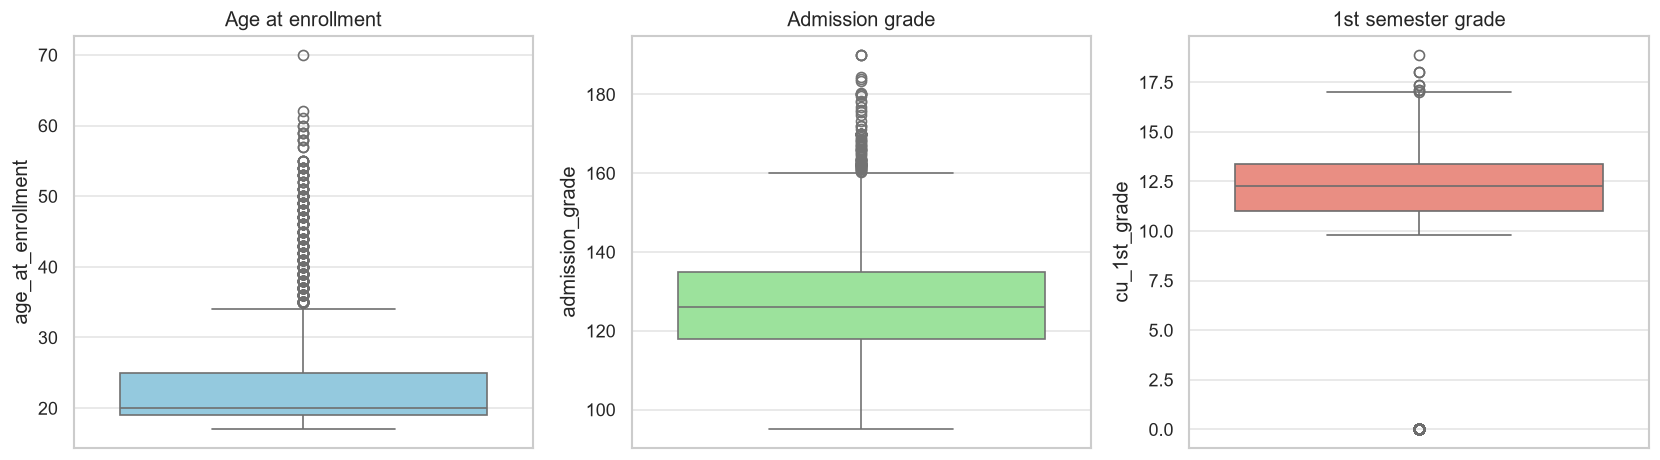

In [8]:
# Aperçu visuel rapide des distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(y=df["age_at_enrollment"], ax=axes[0], color="skyblue")
axes[0].set_title("Age at enrollment")

sns.boxplot(y=df["admission_grade"], ax=axes[1], color="lightgreen")
axes[1].set_title("Admission grade")

sns.boxplot(y=df["cu_1st_grade"], ax=axes[2], color="salmon")
axes[2].set_title("1st semester grade")

plt.tight_layout()
plt.show()


## 6. Séparation Variables Catégorielles / Numériques

Beaucoup de variables sont codées en entiers mais sont en réalité **catégorielles**.  
On les sépare explicitement pour la suite du projet (encodage, modélisation…).


In [9]:
categorical_cols = [
    "marital_status", "application_mode", "application_order", "course",
    "daytime_evening_attendance", "previous_qualification", "nationality",
    "mother_qualification", "father_qualification",
    "mother_occupation", "father_occupation",
    "displaced", "educational_special_needs", "debtor",
    "tuition_fees_up_to_date", "gender", "scholarship_holder",
    "international", "target"
]

numerical_cols = [
    "previous_qualification_grade", "admission_grade", "age_at_enrollment",
    "cu_1st_credited", "cu_1st_enrolled", "cu_1st_evaluations",
    "cu_1st_approved", "cu_1st_grade", "cu_1st_without_evaluations",
    "cu_2nd_credited", "cu_2nd_enrolled", "cu_2nd_evaluations",
    "cu_2nd_approved", "cu_2nd_grade", "cu_2nd_without_evaluations",
    "unemployment_rate", "inflation_rate", "gdp"
]

# Sécurité : ne garder que les colonnes réellement présentes
categorical_cols = [c for c in categorical_cols if c in df.columns]
numerical_cols   = [c for c in numerical_cols if c in df.columns]

print(f"Variables catégorielles : {len(categorical_cols)}")
print(f"Variables numériques   : {len(numerical_cols)}")
print(f"Total                 : {len(categorical_cols) + len(numerical_cols)} / {df.shape[1]}")


Variables catégorielles : 19
Variables numériques   : 18
Total                 : 37 / 37


In [10]:
# Conversion en type category
for col in categorical_cols:
    df[col] = df[col].astype("category")

print("→ Colonnes catégorielles converties en dtype 'category'")


→ Colonnes catégorielles converties en dtype 'category'


In [19]:
# Aperçu des modalités de la variable cible
print("Répartition de la variable cible :")
print(df["target"].value_counts(dropna=False))

print("\nPourcentages :")
print((df["target"].value_counts(normalize=True) * 100).round(2))

Répartition de la variable cible :
target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Pourcentages :
target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


In [15]:
# Statistiques descriptives des variables numériques
df[numerical_cols].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
previous_qualification_grade,4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
admission_grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
age_at_enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
cu_1st_credited,4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
cu_1st_enrolled,4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
cu_1st_evaluations,4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
cu_1st_approved,4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
cu_1st_grade,4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
cu_1st_without_evaluations,4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00
cu_2nd_credited,4424.0,0.54,1.92,0.00,0.00,0.00,0.00,19.00


## 7. Analyse de la variable cible et des facteurs de risque

On regarde comment le statut final de l'étudiant (`Dropout` / `Enrolled` / `Graduate`)  
varie selon les principales variables de risque (bourse, dettes, notes, âge…).


,Count,Percentage (%)
target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


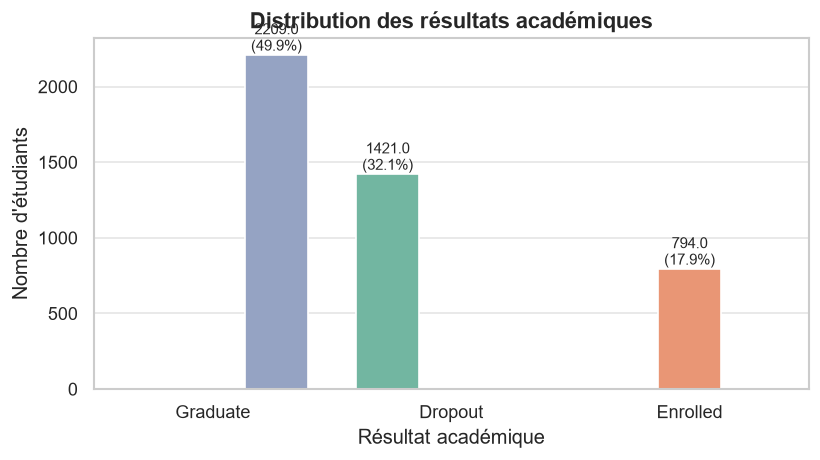

In [20]:
# Distribution de la cible
target_counts = df["target"].value_counts()
target_pct = df["target"].value_counts(normalize=True).mul(100).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_pct
})
display(target_summary)

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="target", hue="target",
                   order=target_counts.index, legend=False)
plt.title("Distribution des résultats académiques", fontsize=13, fontweight="bold")
plt.xlabel("Résultat académique")
plt.ylabel("Nombre d'étudiants")

total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height}\n({height/total*100:.1f}%)",
                (p.get_x() + p.get_width()/2, height),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


In [22]:
# Crosstabs avec les facteurs de risque binaires
key_cats = [
    "gender", "scholarship_holder", "debtor",
    "tuition_fees_up_to_date", "daytime_evening_attendance",
    "displaced", "international"
]
key_cats = [c for c in key_cats if c in df.columns]

for col in key_cats:
    print(f"\n▶ {col.upper()} vs TARGET (en pourcentages)")
    ct = pd.crosstab(df[col], df["target"], normalize="index").mul(100).round(1)
    display(ct)



▶ GENDER vs TARGET (pourcentages en ligne)


target,Dropout,Enrolled,Graduate
gender,,,
0,25.1,17.0,57.9
1,45.1,19.7,35.2



▶ SCHOLARSHIP_HOLDER vs TARGET (pourcentages en ligne)


target,Dropout,Enrolled,Graduate
scholarship_holder,,,
0,38.7,20.0,41.3
1,12.2,11.8,76.0



▶ DEBTOR vs TARGET (pourcentages en ligne)


target,Dropout,Enrolled,Graduate
debtor,,,
0,28.3,18.0,53.8
1,62.0,17.9,20.1


... (4 outputs left out)


▶ DISPLACED vs TARGET (pourcentages en ligne)


target,Dropout,Enrolled,Graduate
displaced,,,
0,37.6,18.1,44.3
1,27.6,17.8,54.6



▶ INTERNATIONAL vs TARGET (pourcentages en ligne)


target,Dropout,Enrolled,Graduate
international,,,
0,32.2,17.8,50.0
1,29.1,21.8,49.1


In [23]:
# Statistiques des variables numériques selon la cible
key_nums = [
    "age_at_enrollment", "admission_grade", "previous_qualification_grade",
    "cu_1st_grade", "cu_2nd_grade", "cu_1st_approved", "cu_2nd_approved"
]
key_nums = [c for c in key_nums if c in df.columns]

display(df.groupby("target", observed=True)[key_nums].agg(["mean", "median", "std"]).round(2))


age_at_enrollment              admission_grade                \
                      mean median   std            mean median    std   
target                                                                  
Dropout              26.07   23.0  8.70          124.96  123.6  15.13   
Enrolled             22.37   20.0  6.30          125.53  124.1  13.79   
Graduate             21.78   19.0  6.69          128.79  127.4  14.07   

         previous_qualification_grade               cu_1st_grade  ...        \
                                 mean median    std         mean  ...   std   
target                                                            ...         
Dropout                        131.11  133.1  12.87         7.26  ...  6.03   
Enrolled                       131.21  130.0  12.87        11.13  ...  3.68   
Graduate                       134.08  133.1  13.34        12.64  ...  2.70   

         cu_2nd_grade              cu_1st_approved               \
                 mean median   std            mean median   std   
target                                                            
Dropout          5.90    0.0  6.12            2.55    2.0  2.86   
Enrolled        11.12   12.0  3.60            4.32    5.0  2.29   
Graduate        12.70   13.0  2.69            6.23    6.0  2.58   

         cu_2nd_approved               
                    mean median   std  
target                                 
Dropout             1.94    0.0  2.57  
Enrolled            4.06    4.0  2.18  
Graduate            6.18    6.0  2.27  

[3 rows x 21 columns]

## 8. Visualisations principales

Ces graphiques servent à illustrer les premiers profils d'étudiants à risque.


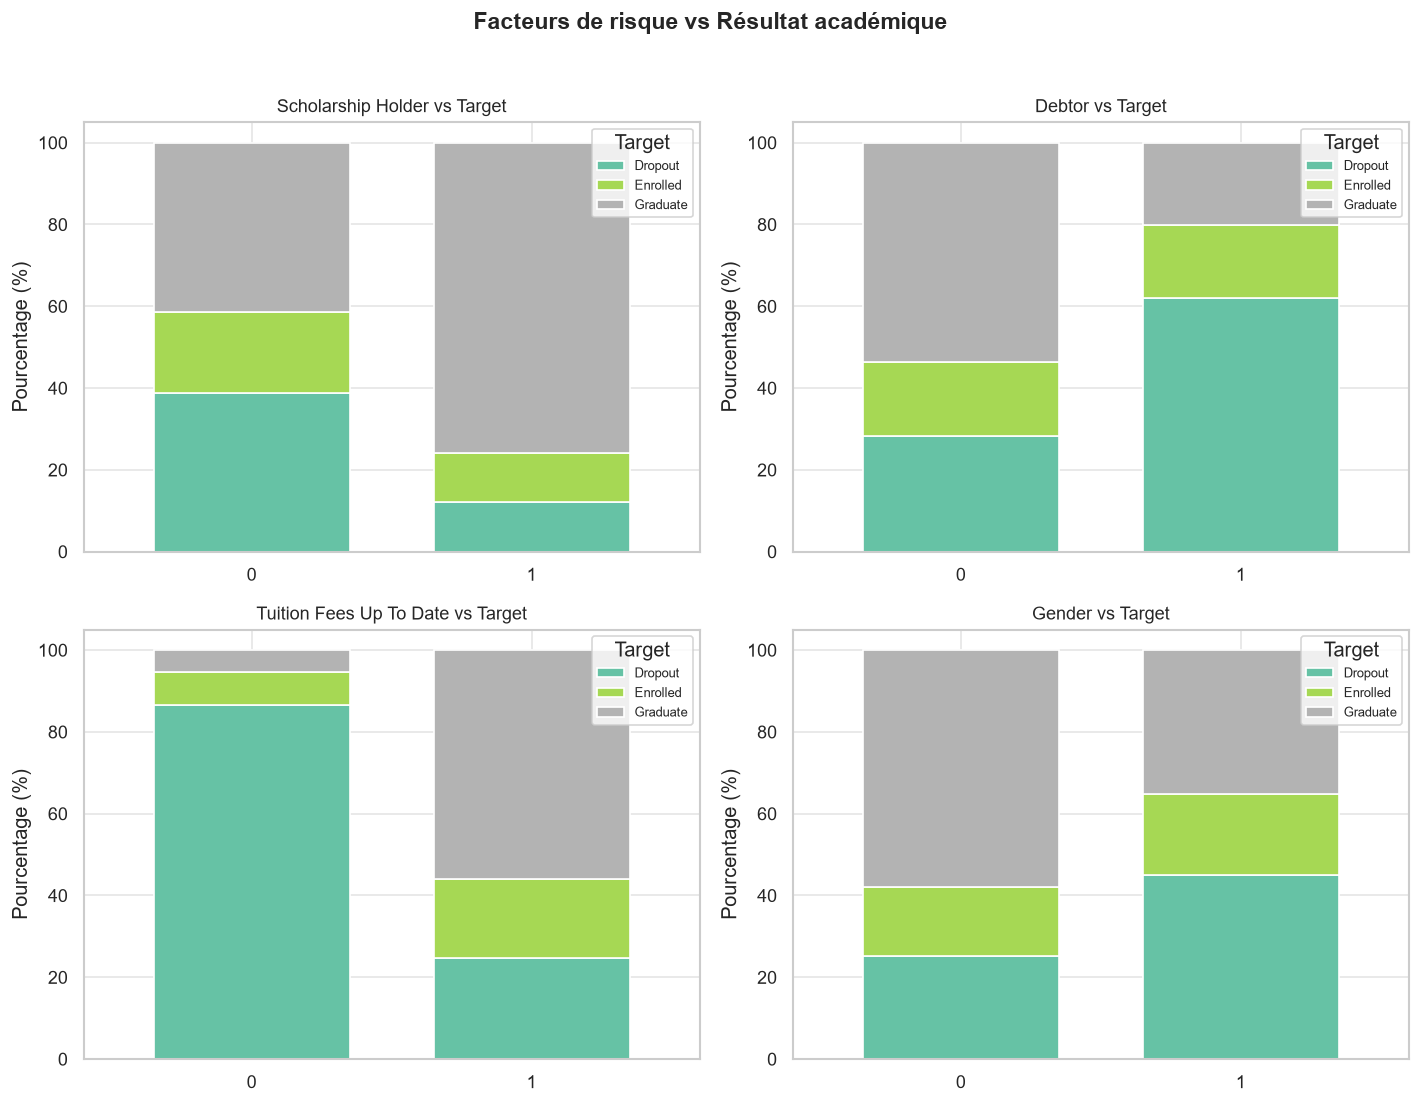

In [24]:
# Facteurs de risque vs Target (barres empilées)
risk_factors = ["scholarship_holder", "debtor", "tuition_fees_up_to_date", "gender"]
risk_factors = [c for c in risk_factors if c in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(risk_factors):
    ct = pd.crosstab(df[col], df["target"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=axes[i], colormap="Set2", width=0.7)
    axes[i].set_title(f"{col.replace('_', ' ').title()} vs Target", fontsize=11)
    axes[i].set_ylabel("Pourcentage (%)")
    axes[i].set_xlabel("")
    axes[i].legend(title="Target", loc="upper right", fontsize=8)
    axes[i].tick_params(axis="x", rotation=0)

plt.suptitle("Facteurs de risque vs Résultat académique", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


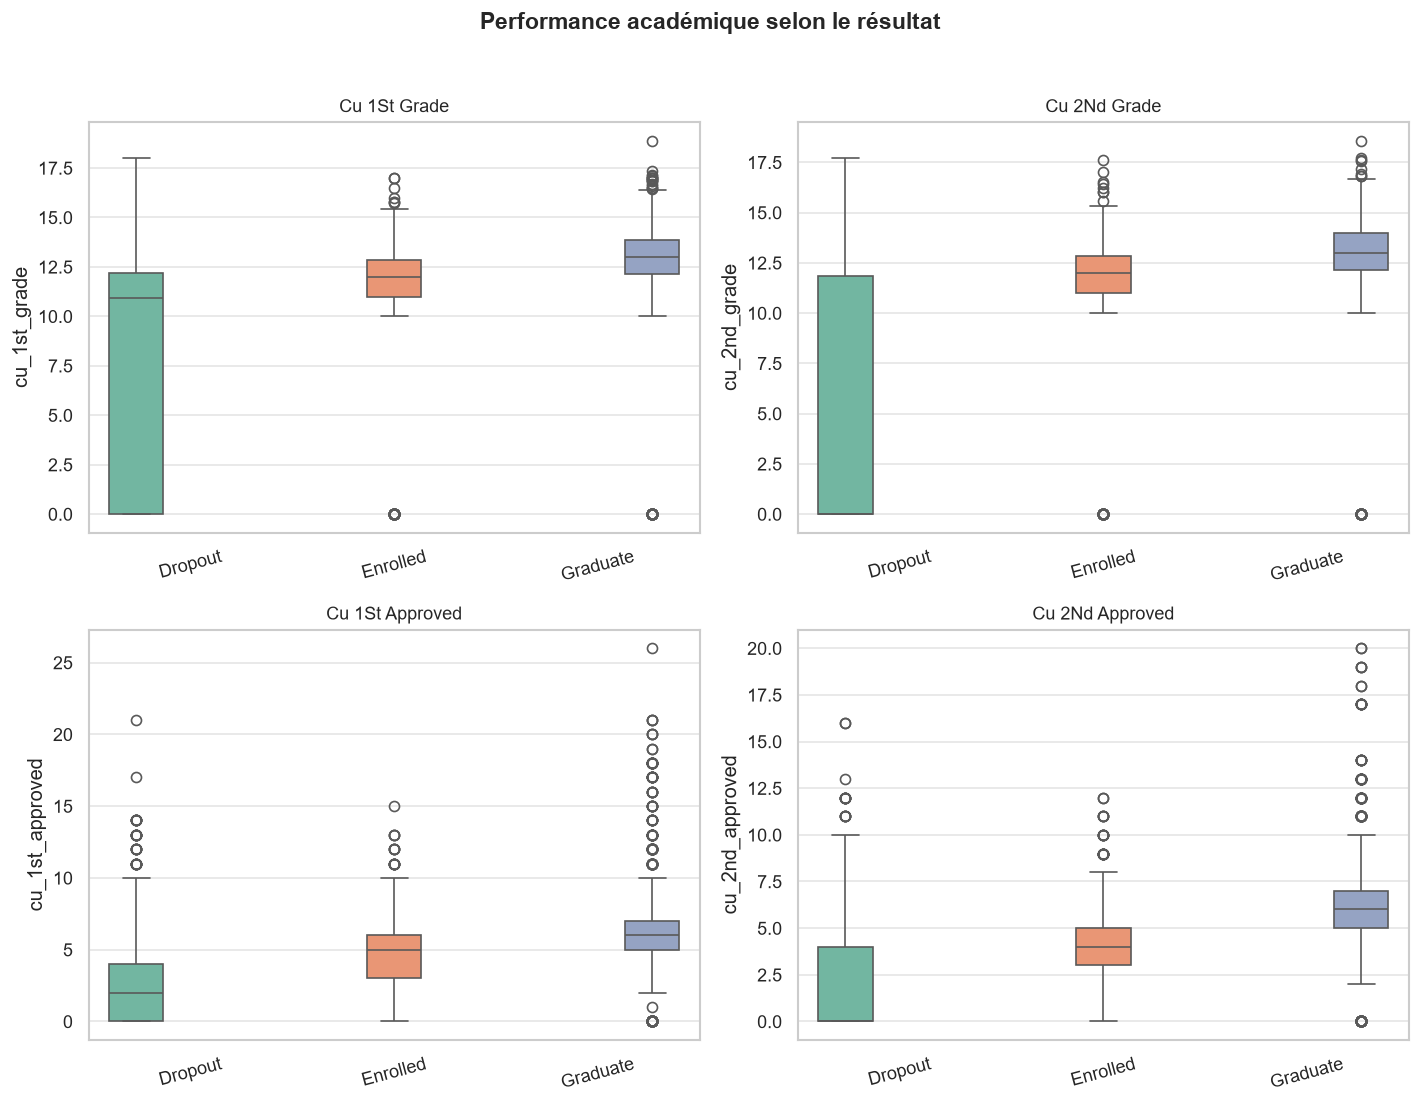

In [25]:
# Performance académique selon le résultat
perf_cols = ["cu_1st_grade", "cu_2nd_grade", "cu_1st_approved", "cu_2nd_approved"]
perf_cols = [c for c in perf_cols if c in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(perf_cols):
    sns.boxplot(data=df, x="target", y=col, hue="target", ax=axes[i], legend=False)
    axes[i].set_title(col.replace("_", " ").title(), fontsize=11)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=15)

plt.suptitle("Performance académique selon le résultat", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


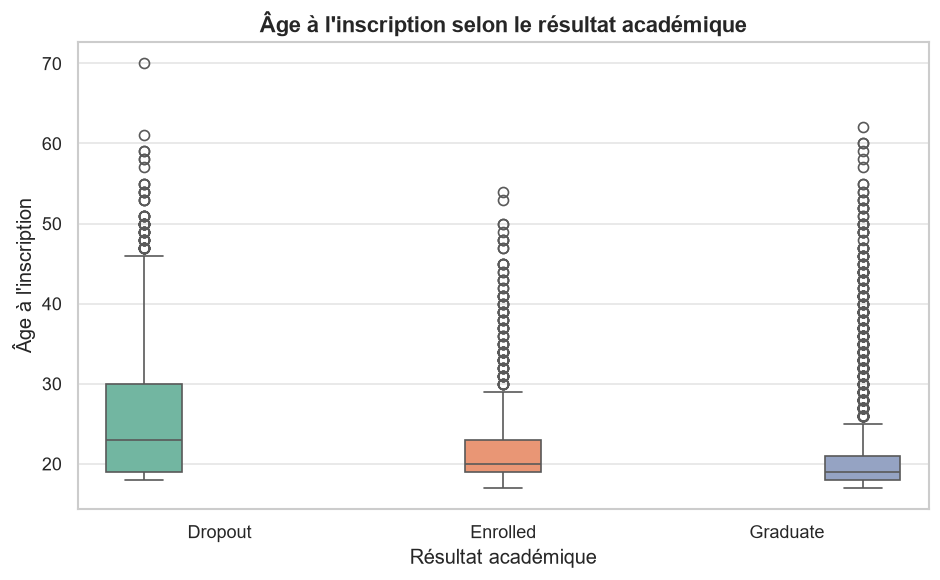

In [26]:
# Âge à l'inscription selon le résultat
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="target", y="age_at_enrollment", hue="target", legend=False)
plt.title("Âge à l'inscription selon le résultat académique", fontsize=13, fontweight="bold")
plt.xlabel("Résultat académique")
plt.ylabel("Âge à l'inscription")
plt.tight_layout()
plt.show()


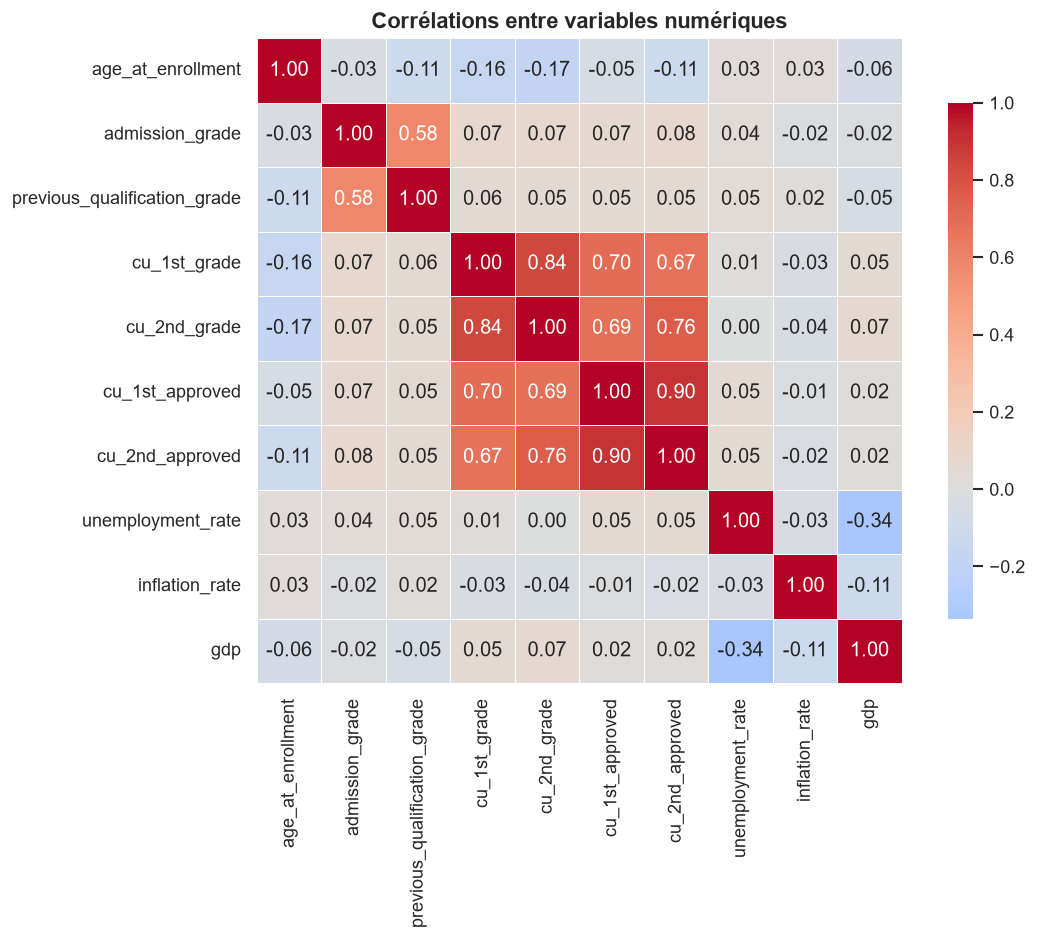

In [27]:
# Heatmap de corrélation (variables numériques)
num_for_corr = [
    "age_at_enrollment", "admission_grade", "previous_qualification_grade",
    "cu_1st_grade", "cu_2nd_grade", "cu_1st_approved", "cu_2nd_approved",
    "unemployment_rate", "inflation_rate", "gdp"
]
num_for_corr = [c for c in num_for_corr if c in df.columns]

plt.figure(figsize=(10, 8))
corr = df[num_for_corr].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Corrélations entre variables numériques", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 9. Sauvegarde du dataset nettoyé

On exporte la version propre qui servira pour les étapes suivantes  
(corrélations approfondies, feature engineering et modélisation).


In [28]:
OUTPUT_PATH = Path("../dataset/processed/student_data_clean.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_PATH, index=False)
print(f"Dataset nettoyé sauvegardé → {OUTPUT_PATH}")
print(f"Shape finale : {df.shape}")


Dataset nettoyé sauvegardé → ..\dataset\processed\student_data_clean.csv
Shape finale : (4424, 37)
